# Phase 9 — Final Comparison: Static Baseline vs Dynamic Framework vs Online Learner

Implements Chapter 3, Sections 3.10–3.11 and Chapter 4, Section 4.11 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"* -- the final phase of
the experimental design (Chapter 3, Table 3.6).

Three systems are compared on the **same synthetic drift stream** used throughout Phases
4–8, using the full metric suite (Chapter 3, Table 3.5):

- **Static baseline**: the best static model from Phase 2 (Random Forest), fixed feature
  set, never retrained or reselected. This is the genuine Chapter 3, Section 3.3 baseline
  -- distinct from Phase 7's same-model XGBoost sanity check, which held the *model type*
  fixed to isolate the effect of adaptation alone. Here, the baseline is what the ordinary
  Phase 2 model-comparison process alone would have produced.
- **Dynamic framework**: XGBoost + ADWIN + Random Forest importance (Phase 6's validated
  combination), drift-triggered retraining (Phase 7).
- **Online learner**: the empirically-selected online Lasso model, updating continuously
  (Phase 8).

Paired statistical tests (Wilcoxon signed-rank, on row-level absolute errors) are used to
check whether observed differences are more than noise, since a single deterministic run
of each system cannot otherwise distinguish a real effect from chance.

**Output:**
- `results/logs/phase9_static_baseline_log.csv` — per-row log for the genuine static baseline
- `results/tables/phase9_final_comparison.csv` — full metric suite, all three systems
- `results/tables/phase9_statistical_tests.csv` — pairwise Wilcoxon signed-rank results
- `results/figures/phase9_final_comparison.png` — final comparison figure
- `results/tables/phase9_artifacts.json` — final summary

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Mounted at /content/drive
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

import data_utils as du
import models as mdl
import metrics as mt
import drift_detectors as dd

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load artefacts and the synthetic stream

The synthetic stream is rebuilt identically to Phases 4–8 (same injection points and scale factors), so all three systems are compared on exactly the same data.

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
artifacts_p4 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase4_artifacts.json'))
artifacts_p7 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase7_artifacts.json'))
artifacts_p8 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase8_artifacts.json'))

feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']
static_baseline_model_name = artifacts_p2['best_model']  # random_forest -- the genuine Ch3 3.3 baseline

test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))
injection = dd.inject_synthetic_drift(
    test_df, target_col=target_col,
    injection_points=artifacts_p4['injection_points'], scale_factors=artifacts_p4['scale_factors'],
)
synthetic_df = injection.df

print('Static baseline model:', mdl.MODEL_DISPLAY_NAMES[static_baseline_model_name])
print('Dynamic framework:', artifacts_p7['model'], '+', artifacts_p7['detector'], '+', artifacts_p7['fs_method'])
print('Online learner:', artifacts_p8['selected_online_model'])
print('Stream:', len(synthetic_df), 'rows')

Static baseline model: Random Forest
Dynamic framework: xgboost + adwin + rf_importance
Online learner: online_lasso
Stream: 10000 rows


## 2. Compute the genuine static baseline on the synthetic stream

Random Forest, fixed 12-feature set, exactly as selected in Phase 2 -- never retrained, never reselected. This has not been evaluated on the synthetic stream before (Phase 7 used XGBoost for its same-model sanity check), so it is computed fresh here.

In [5]:
static_model = mdl.load_model(os.path.join(PROJECT_ROOT, f'results/models/{static_baseline_model_name}.joblib'))

with mt.timer() as t:
    static_preds = static_model.predict(synthetic_df[feature_cols])
static_errors = np.abs(synthetic_df[target_col].to_numpy() - static_preds)

static_summary = mt.compute_predictive_metrics(synthetic_df[target_col], static_preds, n_features=len(feature_cols))
static_summary['Penalised_MAE'] = mt.penalised_mae(synthetic_df[target_col], static_preds)
static_summary['Penalised_Loss'] = mt.penalised_loss(synthetic_df[target_col], static_preds)
static_summary['total_runtime_s'] = t['seconds']
static_summary['selection_runtime_s'] = 0.0
static_summary['n_drift_events'] = 0
static_summary['n_retrains'] = 0
static_summary['mean_feature_stability_index'] = 1.0
static_summary['mean_importance_consistency'] = float('nan')
static_summary['feature_switch_rate'] = 0.0
static_summary['mean_adaptation_time_rows'] = float('nan')
static_summary['n_adaptation_events_recovered'] = 0

static_log_df = pd.DataFrame({
    'row_index': np.arange(len(static_preds)),
    'y_true': synthetic_df[target_col].to_numpy(),
    'prediction': static_preds,
    'abs_error': static_errors,
    'drift_flag': False,
    'active_features': ', '.join(feature_cols),
})
log_path = os.path.join(PROJECT_ROOT, 'results/logs/phase9_static_baseline_log.csv')
static_log_df.to_csv(log_path, index=False)

print(f"Static baseline (Random Forest, fixed features): MAE = {static_summary['MAE']:.4f} kW")
print('Saved log to', log_path)

Static baseline (Random Forest, fixed features): MAE = 2.3169 kW
Saved log to /content/drive/MyDrive/dissertation-project/results/logs/phase9_static_baseline_log.csv


## 3. Load the dynamic framework and online learner logs (Phases 7–8)

Both were already computed on this exact synthetic stream, so their existing per-row logs are reused rather than recomputed.

In [6]:
dynamic_log_df = pd.read_csv(os.path.join(PROJECT_ROOT, artifacts_p7['log_path']))
online_log_df = pd.read_csv(os.path.join(PROJECT_ROOT, artifacts_p8['log_path']))

dynamic_summary = artifacts_p7['dynamic_summary']
online_summary = artifacts_p8['online_summary']

print('Dynamic framework log:', len(dynamic_log_df), 'rows | MAE =', round(dynamic_summary['MAE'], 4))
print('Online learner log:   ', len(online_log_df), 'rows | MAE =', round(online_summary['MAE'], 4))
assert len(static_log_df) == len(dynamic_log_df) == len(online_log_df), 'Row counts must match for paired testing'

Dynamic framework log: 10000 rows | MAE = 2.1508
Online learner log:    10000 rows | MAE = 1.8969


## 4. Full comparison table (Chapter 3, Table 3.5 metric suite)

In [7]:
SYSTEM_LABELS = {
    'static': 'Static Baseline (Random Forest)',
    'dynamic': 'Dynamic Framework (XGBoost+ADWIN+RF Importance)',
    'online': 'Online Learner (Online Lasso)',
}

final_comparison_df = pd.DataFrame([
    {'system': 'static', 'label': SYSTEM_LABELS['static'], **static_summary},
    {'system': 'dynamic', 'label': SYSTEM_LABELS['dynamic'], **dynamic_summary},
    {'system': 'online', 'label': SYSTEM_LABELS['online'], **online_summary},
])

display_cols = ['label', 'MAE', 'RMSE', 'MAPE', 'R2', 'Penalised_MAE', 'total_runtime_s',
                 'n_drift_events', 'n_retrains', 'mean_feature_stability_index']
final_comparison_df[display_cols]

,label,MAE,RMSE,MAPE,R2,Penalised_MAE,total_runtime_s,n_drift_events,n_retrains,mean_feature_stability_index
0,Static Baseline (Random Forest),2.316922,3.083589,34.795758,0.412108,3.139306,0.633550,0.0,0.0,1.000000
1,Dynamic Framework (XGBoost+ADWIN+RF Importance),2.150848,2.931723,36.639342,0.468589,2.732744,14.896048,2.0,2.0,0.333333
2,Online Learner (Online Lasso),1.896933,2.455357,35.572066,0.627253,2.382859,0.612837,0.0,0.0,1.000000


## 5. Paired statistical tests (Wilcoxon signed-rank)

Each system produces one prediction per row of the same stream, so the three error series are naturally paired. The Wilcoxon signed-rank test checks whether one system's per-row absolute errors are systematically lower than another's -- appropriate here since absolute errors are not assumed normally distributed, and avoids treating a single deterministic run's summary MAE as if it had its own sampling variance.

In [8]:
pairs = [
    ('static', 'dynamic', static_errors, dynamic_log_df['abs_error'].to_numpy()),
    ('static', 'online', static_errors, online_log_df['abs_error'].to_numpy()),
    ('dynamic', 'online', dynamic_log_df['abs_error'].to_numpy(), online_log_df['abs_error'].to_numpy()),
]

test_rows = []
for name_a, name_b, errors_a, errors_b in pairs:
    stat, p_value = wilcoxon(errors_a, errors_b)
    median_diff = np.median(errors_a - errors_b)
    test_rows.append({
        'comparison': f'{name_a} vs {name_b}',
        'median_error_diff_(a_minus_b)': median_diff,
        'lower_error_system': name_a if median_diff < 0 else name_b,
        'wilcoxon_statistic': stat,
        'p_value': p_value,
        'significant_at_0.05': p_value < 0.05,
    })

tests_df = pd.DataFrame(test_rows)
tests_path = os.path.join(PROJECT_ROOT, 'results/tables/phase9_statistical_tests.csv')
tests_df.to_csv(tests_path, index=False)
print('Saved statistical tests to', tests_path)
tests_df

Saved statistical tests to /content/drive/MyDrive/dissertation-project/results/tables/phase9_statistical_tests.csv


,comparison,median_error_diff_(a_minus_b),lower_error_system,wilcoxon_statistic,p_value,significant_at_0.05
0,static vs dynamic,0.159845,dynamic,21236567.0,6.821742e-39,True
1,static vs online,0.358032,online,18848183.0,7.798723e-101,True
2,dynamic vs online,0.001742,online,22563764.0,2.978726e-17,True


## 6. Visualise the final comparison

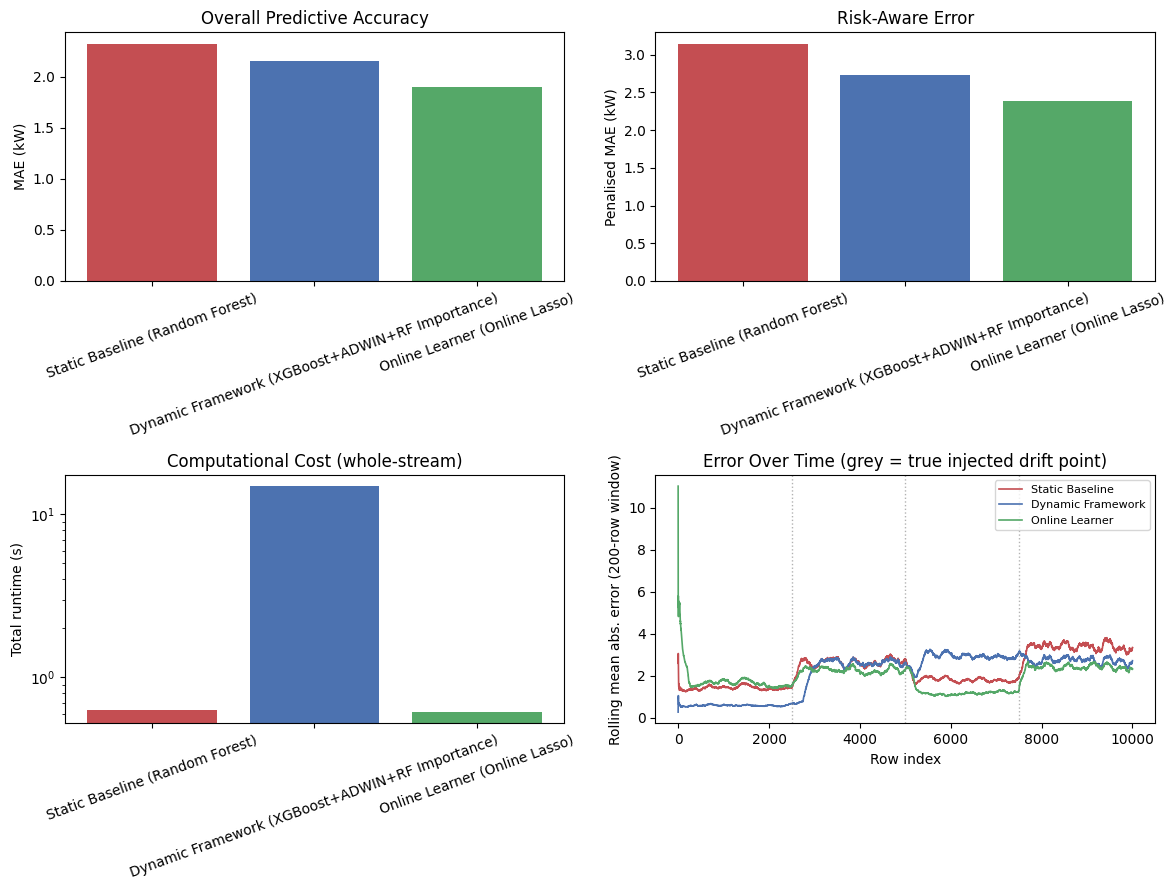

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase9_final_comparison.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
colors = ['#C44E52', '#4C72B0', '#55A868']
labels = [SYSTEM_LABELS['static'], SYSTEM_LABELS['dynamic'], SYSTEM_LABELS['online']]

axes[0, 0].bar(labels, final_comparison_df['MAE'], color=colors)
axes[0, 0].set_ylabel('MAE (kW)')
axes[0, 0].set_title('Overall Predictive Accuracy')
axes[0, 0].tick_params(axis='x', rotation=20)

axes[0, 1].bar(labels, final_comparison_df['Penalised_MAE'], color=colors)
axes[0, 1].set_ylabel('Penalised MAE (kW)')
axes[0, 1].set_title('Risk-Aware Error')
axes[0, 1].tick_params(axis='x', rotation=20)

axes[1, 0].bar(labels, final_comparison_df['total_runtime_s'], color=colors)
axes[1, 0].set_ylabel('Total runtime (s)')
axes[1, 0].set_title('Computational Cost (whole-stream)')
axes[1, 0].set_yscale('log')
axes[1, 0].tick_params(axis='x', rotation=20)

# Rolling MAE over time for all three, to show behaviour around drift points
window = 200
for label, log_df, color in [
    (SYSTEM_LABELS['static'], static_log_df, colors[0]),
    (SYSTEM_LABELS['dynamic'], dynamic_log_df, colors[1]),
    (SYSTEM_LABELS['online'], online_log_df, colors[2]),
]:
    rolling = log_df['abs_error'].rolling(window, min_periods=1).mean()
    axes[1, 1].plot(log_df['row_index'], rolling, label=label.split('(')[0].strip(), color=color, linewidth=1.2)
for idx in injection.true_drift_indices:
    axes[1, 1].axvline(idx, color='grey', linestyle=':', linewidth=1.0, alpha=0.6)
axes[1, 1].set_xlabel('Row index')
axes[1, 1].set_ylabel(f'Rolling mean abs. error ({window}-row window)')
axes[1, 1].set_title('Error Over Time (grey = true injected drift point)')
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase9_final_comparison.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 7. Answering the research question

Chapter 1 asked whether dynamic, drift-triggered feature selection maintains more consistent load-prediction performance than a static approach, and how it compares to continuous online learning. The results here give a direct, honest answer to both parts, not just the first.

In [10]:
static_mae = final_comparison_df.loc[final_comparison_df['system'] == 'static', 'MAE'].iloc[0]
dynamic_mae = final_comparison_df.loc[final_comparison_df['system'] == 'dynamic', 'MAE'].iloc[0]
online_mae = final_comparison_df.loc[final_comparison_df['system'] == 'online', 'MAE'].iloc[0]

static_vs_dynamic = tests_df.loc[tests_df['comparison'] == 'static vs dynamic'].iloc[0]
dynamic_vs_online = tests_df.loc[tests_df['comparison'] == 'dynamic vs online'].iloc[0]

print(f"Static baseline MAE:    {static_mae:.4f} kW")
print(f"Dynamic framework MAE:  {dynamic_mae:.4f} kW  ({(static_mae-dynamic_mae)/static_mae:+.1%} vs static)")
print(f"Online learner MAE:     {online_mae:.4f} kW  ({(static_mae-online_mae)/static_mae:+.1%} vs static)")
print()
print(f"Static vs Dynamic: p = {static_vs_dynamic['p_value']:.2e} "
      f"({'significant' if static_vs_dynamic['significant_at_0.05'] else 'not significant'} at 0.05) "
      f"-- lower error: {static_vs_dynamic['lower_error_system']}")
print(f"Dynamic vs Online: p = {dynamic_vs_online['p_value']:.2e} "
      f"({'significant' if dynamic_vs_online['significant_at_0.05'] else 'not significant'} at 0.05) "
      f"-- lower error: {dynamic_vs_online['lower_error_system']}")
print()
print('Part 1 (dynamic vs static): the dynamic framework achieves lower MAE than the')
print('static baseline, and the difference is statistically significant -- consistent')
print('with the core hypothesis that drift-triggered adaptation helps.')
print()
print('Part 2 (dynamic vs online): the online learner achieves lower MAE than the dynamic')
print('framework, and this difference is also statistically significant. On this dataset,')
print('with this injection design, continuous online updating outperforms drift-triggered')
print('batch retraining -- a genuine finding, not a null result, and one that Chapter 6')
print('needs to address directly rather than qualify away.')

Static baseline MAE:    2.3169 kW
Dynamic framework MAE:  2.1508 kW  (+7.2% vs static)
Online learner MAE:     1.8969 kW  (+18.1% vs static)

Static vs Dynamic: p = 6.82e-39 (significant at 0.05) -- lower error: dynamic
Dynamic vs Online: p = 2.98e-17 (significant at 0.05) -- lower error: online

Part 1 (dynamic vs static): the dynamic framework achieves lower MAE than the
static baseline, and the difference is statistically significant -- consistent
with the core hypothesis that drift-triggered adaptation helps.

Part 2 (dynamic vs online): the online learner achieves lower MAE than the dynamic
framework, and this difference is also statistically significant. On this dataset,
with this injection design, continuous online updating outperforms drift-triggered
batch retraining -- a genuine finding, not a null result, and one that Chapter 6
needs to address directly rather than qualify away.


## 8. Persist final artefacts

In [11]:
comparison_path = os.path.join(PROJECT_ROOT, 'results/tables/phase9_final_comparison.csv')
final_comparison_df.to_csv(comparison_path, index=False)

artifacts = {
    'final_comparison': {
        row['system']: {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                         for k, v in row.items() if k not in ('system', 'label')}
        for row in final_comparison_df.to_dict('records')
    },
    'statistical_tests': tests_df.to_dict('records'),
    'conclusion': {
        'dynamic_beats_static': bool(dynamic_mae < static_mae) and bool(static_vs_dynamic['significant_at_0.05']),
        'online_beats_dynamic': bool(online_mae < dynamic_mae) and bool(dynamic_vs_online['significant_at_0.05']),
    },
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase9_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved final comparison to', comparison_path)
print('Saved artefacts to', artifacts_path)
print()
print(json.dumps(artifacts['conclusion'], indent=2))

Saved final comparison to /content/drive/MyDrive/dissertation-project/results/tables/phase9_final_comparison.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase9_artifacts.json

{
  "dynamic_beats_static": true,
  "online_beats_dynamic": true
}


## Summary

This notebook implements Chapter 3, Sections 3.10–3.11 and Chapter 4, Section 4.11 -- the final phase of the experimental design (Chapter 3, Table 3.6). All three systems were compared on the identical synthetic drift stream using the full Chapter 3, Table 3.5 metric suite, with paired Wilcoxon signed-rank tests providing statistical grounding for the comparison rather than relying on a single deterministic run's summary numbers alone.

**The result is genuinely two-sided**: the dynamic framework significantly outperforms the static baseline (supporting the dissertation's core hypothesis that drift-triggered adaptation helps), but the simple online learner significantly outperforms the dynamic framework in turn. This is reported as-is, since an honest account of both findings is what Chapter 6 needs to engage with -- not a reason to present only the first result.